In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Objective:** Identify which customer characteristics are associated with credit score (Good / Standard / Poor) in the PaisaBazaar dataset.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset.csv', low_memory=False)
original_df=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/dataset.csv",low_memory=False)

**Summary of Data**

In [9]:
df.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,Aaron Maashoh,23.0,821000265.0,Scientist,19114.12,1824.843333,3.0,...,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

In [11]:
df[df.isnull().any(axis=1)]

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score


**Cleaning and Assingning correct datatype to features in dataset**

In [12]:
df.drop(['Name','SSN','ID'],inplace=True,axis=1)       # drop unwanted columns

In [13]:
df['Annual_Inhand_Income']=df['Monthly_Inhand_Salary']*12           # creating inhand annual income which is more accurate

In [14]:
df.drop(['Annual_Income'],inplace=True,axis=1)    # dropping this colmn as we have above one

In [15]:
df.isnull().sum()

,0
Customer_ID,0
Month,0
Age,0
Occupation,0
Monthly_Inhand_Salary,0
Num_Bank_Accounts,0
Num_Credit_Card,0
Interest_Rate,0
Num_of_Loan,0
Type_of_Loan,0


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Customer_ID               100000 non-null  int64  
 1   Month                     100000 non-null  int64  
 2   Age                       100000 non-null  float64
 3   Occupation                100000 non-null  object 
 4   Monthly_Inhand_Salary     100000 non-null  float64
 5   Num_Bank_Accounts         100000 non-null  float64
 6   Num_Credit_Card           100000 non-null  float64
 7   Interest_Rate             100000 non-null  float64
 8   Num_of_Loan               100000 non-null  float64
 9   Type_of_Loan              100000 non-null  object 
 10  Delay_from_due_date       100000 non-null  float64
 11  Num_of_Delayed_Payment    100000 non-null  float64
 12  Changed_Credit_Limit      100000 non-null  float64
 13  Num_Credit_Inquiries      100000 non-null  fl

In [17]:
df.loc[:,['Num_Bank_Accounts','Delay_from_due_date','Num_of_Delayed_Payment','Changed_Credit_Limit','Outstanding_Debt','Credit_Mix','Interest_Rate','Payment_of_Min_Amount']]

,Num_Bank_Accounts,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Outstanding_Debt,Credit_Mix,Interest_Rate,Payment_of_Min_Amount
0,3.0,3.0,7.0,11.27,809.98,Good,3.0,No
1,3.0,3.0,4.0,11.27,809.98,Good,3.0,No
2,3.0,3.0,7.0,11.27,809.98,Good,3.0,No
3,3.0,5.0,4.0,6.27,809.98,Good,3.0,No
4,3.0,6.0,4.0,11.27,809.98,Good,3.0,No
...,...,...,...,...,...,...,...,...
99995,4.0,23.0,7.0,11.50,502.38,Good,7.0,No
99996,4.0,18.0,7.0,11.50,502.38,Good,7.0,No
99997,4.0,27.0,6.0,11.50,502.38,Good,7.0,No
99998,4.0,20.0,6.0,11.50,502.38,Good,7.0,No


In [18]:
df[['Delay_from_due_date','Num_of_Delayed_Payment']]=df[['Delay_from_due_date','Num_of_Delayed_Payment']].astype(int)    #coverting datatype from float to int as we saw in previous cell



In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Customer_ID               100000 non-null  int64  
 1   Month                     100000 non-null  int64  
 2   Age                       100000 non-null  float64
 3   Occupation                100000 non-null  object 
 4   Monthly_Inhand_Salary     100000 non-null  float64
 5   Num_Bank_Accounts         100000 non-null  float64
 6   Num_Credit_Card           100000 non-null  float64
 7   Interest_Rate             100000 non-null  float64
 8   Num_of_Loan               100000 non-null  float64
 9   Type_of_Loan              100000 non-null  object 
 10  Delay_from_due_date       100000 non-null  int64  
 11  Num_of_Delayed_Payment    100000 non-null  int64  
 12  Changed_Credit_Limit      100000 non-null  float64
 13  Num_Credit_Inquiries      100000 non-null  fl

In [20]:
# focussing on correcting Num_Bank_Accounts column

print(df['Num_Bank_Accounts'].unique())
df[df['Num_Bank_Accounts']=='Nan']

[ 3.  2.  1.  7.  4.  0.  8.  5.  6.  9. 10. 11.]


,Customer_ID,Month,Age,Occupation,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score,Annual_Inhand_Income


In [21]:
df['Payment_of_Min_Amount'].unique()

array(['No', 'NM', 'Yes'], dtype=object)

In [22]:
df['Payment_of_Min_Amount'].mode()

,Payment_of_Min_Amount
0,Yes


In [23]:
## replacing 'NM' with mode value

df['Payment_of_Min_Amount'].replace(to_replace='NM',value=df['Payment_of_Min_Amount'].mode()[0],inplace=True)

print(df['Payment_of_Min_Amount'].unique())

['No' 'Yes']


/tmp/ipykernel_13295/1703740024.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Payment_of_Min_Amount'].replace(to_replace='NM',value=df['Payment_of_Min_Amount'].mode()[0],inplace=True)


**Feature Engineering**

In [24]:
def create_age_grp(age):
    if(age<25):
        return 'Under 25'
    elif(age<35):
        return '25-34'
    elif(age<45):
        return '35-44'
    else:
        return '45+'

df['Age_Group']=df['Age'].apply(create_age_grp)
print(df['Age_Group'])
df.drop('Age',axis=1,inplace=True)

0        Under 25
1        Under 25
2        Under 25
3        Under 25
4        Under 25
           ...   
99995       25-34
99996       25-34
99997       25-34
99998       25-34
99999       25-34
Name: Age_Group, Length: 100000, dtype: object


In [25]:
df['Debt_to_Income_Ratio']=round(df['Outstanding_Debt']/df['Annual_Inhand_Income'],4)        ## Higher value = more debt compared to earnings = higher risk

**Visualisation**

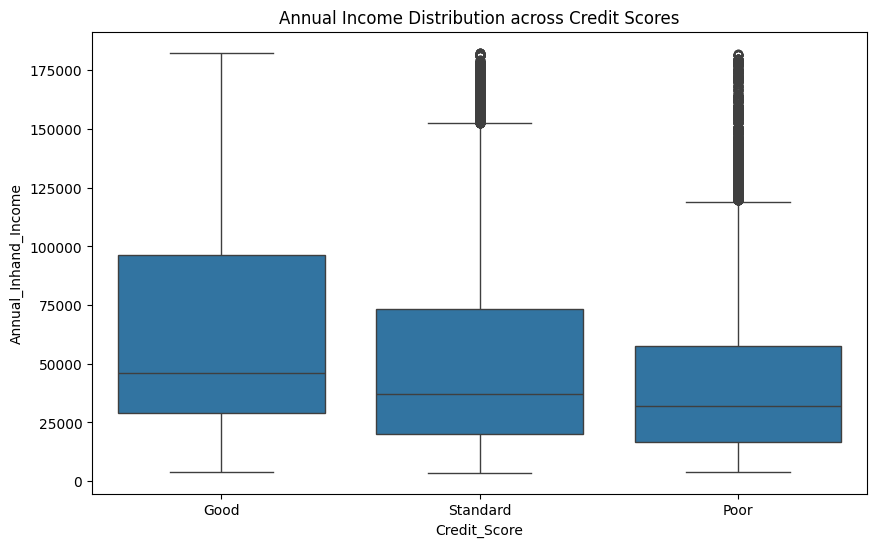

In [26]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Credit_Score', y='Annual_Inhand_Income', data=df, order=['Good', 'Standard', 'Poor'])
plt.title('Annual Income Distribution across Credit Scores')
plt.show()

# Insight on above graph
Income vs. Credit Score Trend: Generally, customers in the Good credit score category have a significantly higher median annual income, while the Standard category follows with a higher salary than the Poor category, which records the lowest income levels.
The Outliers: As we noticed, both the Standard and Poor credit categories have lots of outliers—meaning there are some individuals who earn a high salary (above 150,000+) but still ended up with a Standard or Poor credit score.
# Question: Does a higher annual income correlate with a higher credit score?
Positive Trend: The box plot demonstrates a clear positive correlation. Customers in the Good credit category possess a significantly higher median annual income than those in the Standard and Poor tiers. The Poor credit category records the lowest overall income distribution.
Behavioral vs. Financial Limit:** The presence of high-income outliers ($150,000+) in the Standard and Poor brackets indicates that financial earnings alone do not guarantee a high credit score. Other credit health factors (such as debt-to-income ratio, payment history, and credit utilization) play an equally vital role in determining final credit tiers.

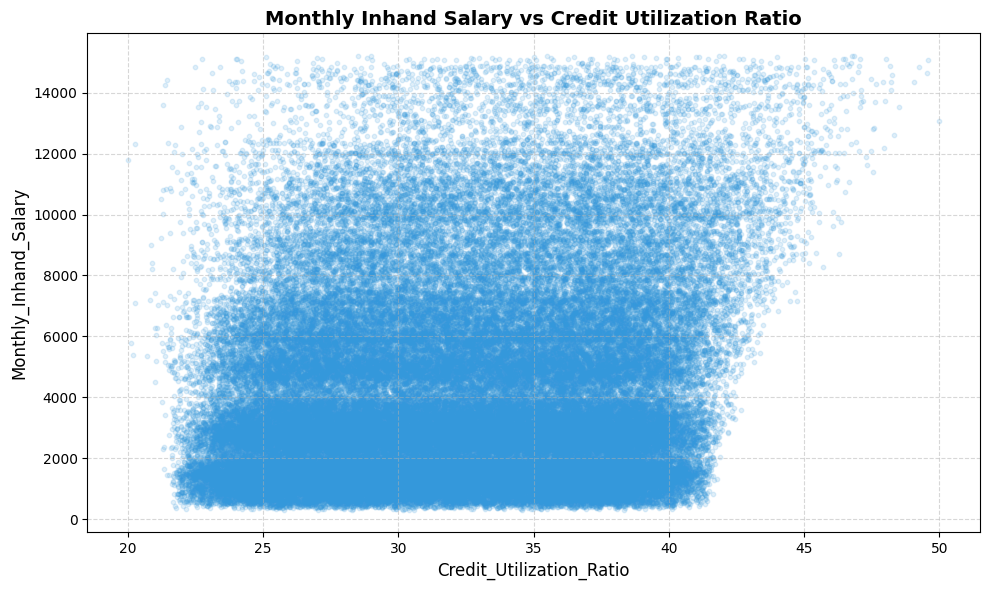

In [27]:
plt.figure(figsize=(10, 6), facecolor='white')
plt.scatter(df['Credit_Utilization_Ratio'], df['Monthly_Inhand_Salary'],
            alpha=0.15, s=10, color='#3498db')
plt.title('Monthly Inhand Salary vs Credit Utilization Ratio', fontsize=14, fontweight='bold')
plt.xlabel('Credit_Utilization_Ratio', fontsize=12)
plt.ylabel('Monthly_Inhand_Salary', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Insight
Credit utilization ratio shows no visible relationship with monthly in-hand salary. Customers at every income level have similar utilization, so income does not explain how much of their credit limit they use

In [28]:
df.groupby('Customer_ID')['Customer_ID'].sum()

,Customer_ID
Customer_ID,
1006,8048
1007,8056
1008,8064
1009,8072
1011,8088
...,...
50984,407872
50990,407920
50992,407936


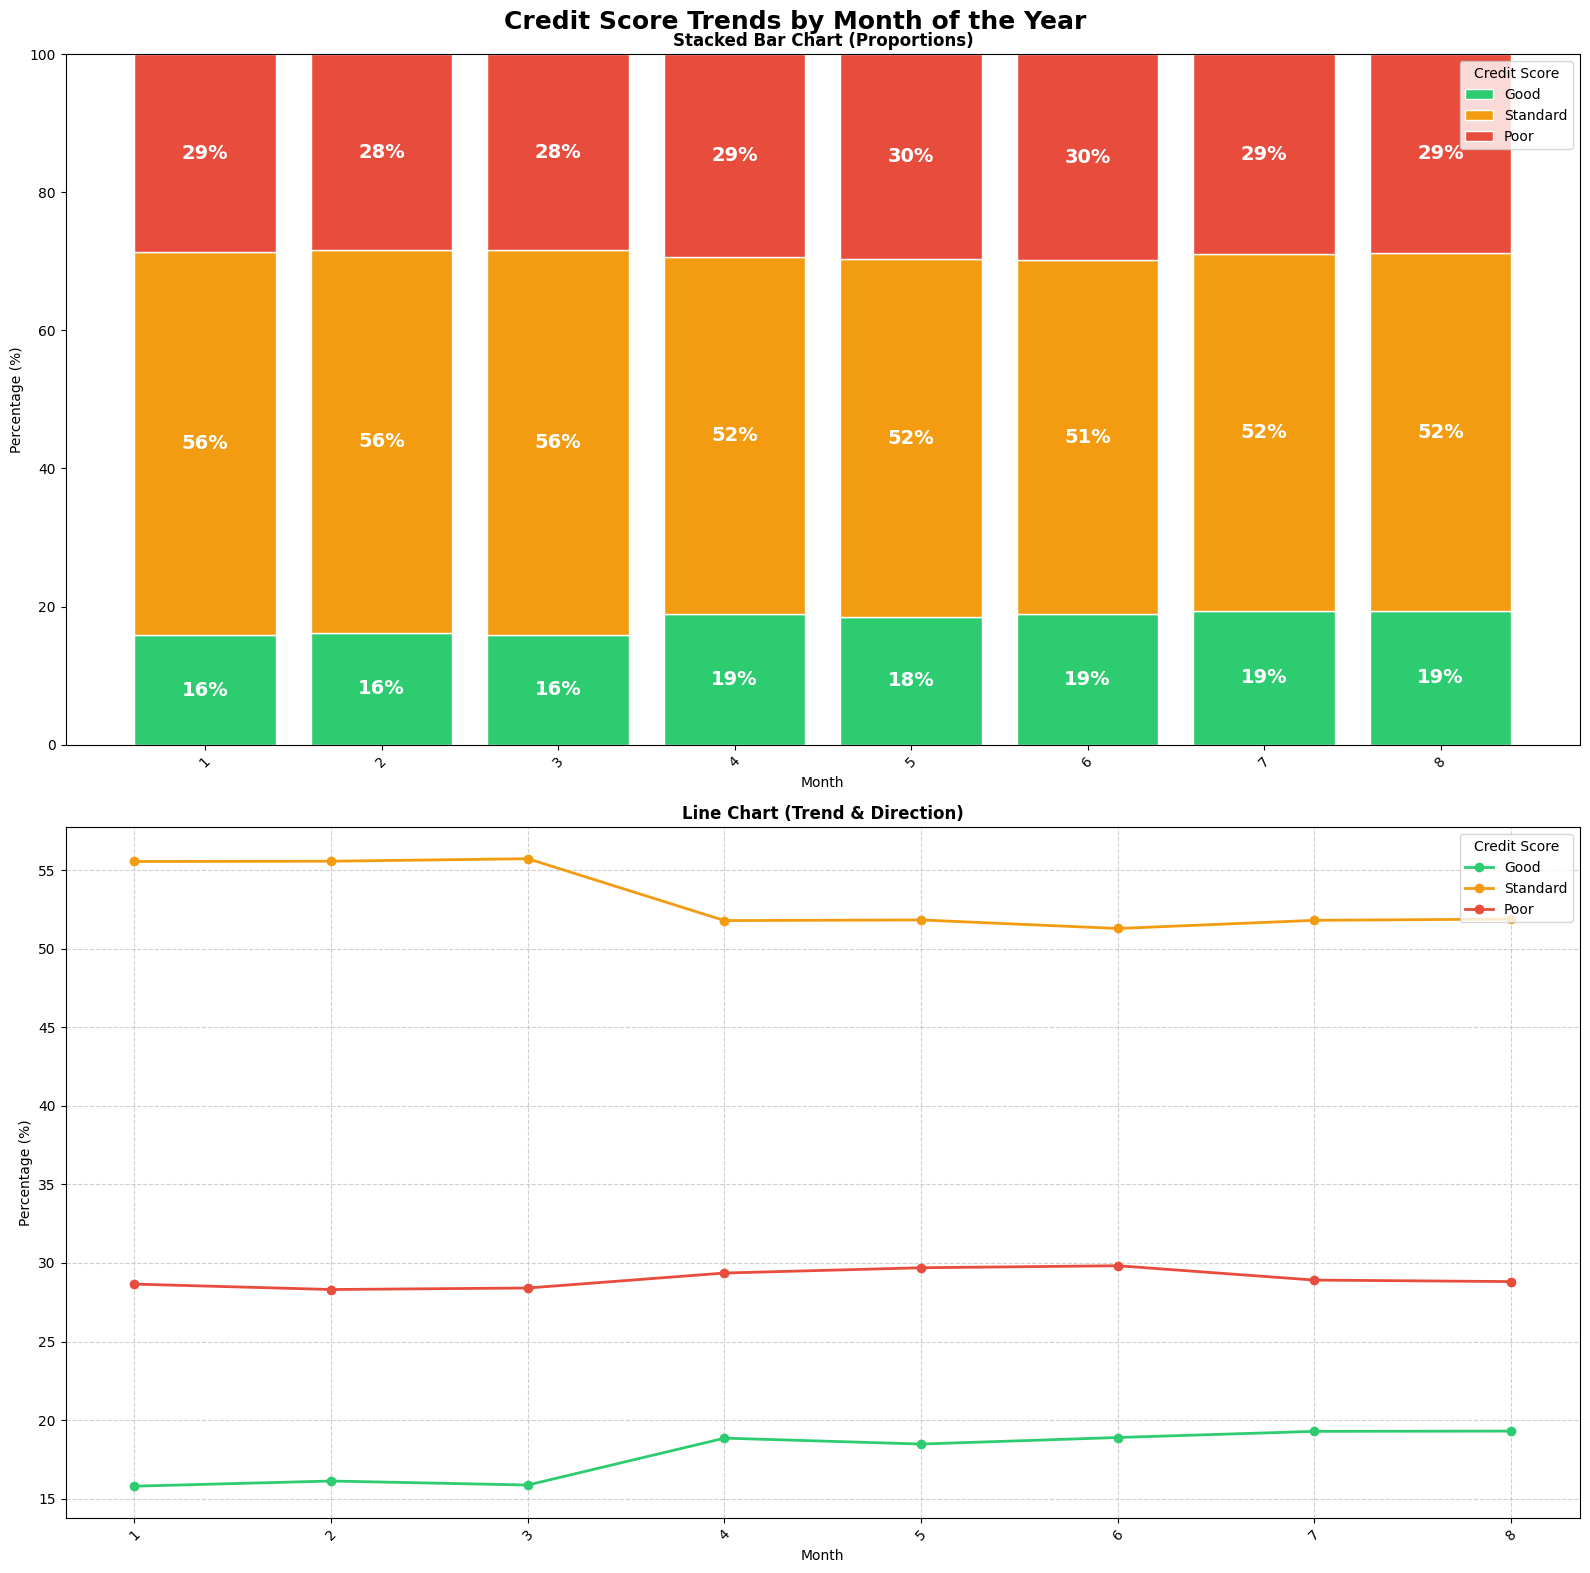

In [35]:

# 1. Prepare the data: counts per Month x Credit_Score, then row-normalize to %
month_credit = (
    df.groupby(['Month', 'Credit_Score'])
      .size()
      .unstack(fill_value=0)
)
month_credit = month_credit.div(month_credit.sum(axis=1), axis=0) * 100

# Order columns nicely
available_cols = [c for c in ['Good', 'Standard', 'Poor'] if c in month_credit.columns]
month_credit = month_credit[available_cols]


if month_credit.index.dtype == object:
    month_credit = month_credit.reindex([m for m in (1,13) if m in month_credit.index])

colors = {'Good': '#2ecc71', 'Standard': '#f39c12', 'Poor': '#e74c3c'}

# 2. Create subplots: 1 row, 2 columns
fig, axes = plt.subplots(2,1, figsize=(16, 16), facecolor='white')
fig.suptitle('Credit Score Trends by Month of the Year', fontsize=18, fontweight='bold')

x = np.arange(len(month_credit))

# --- Plot 1: Stacked Bar Chart
bottom = np.zeros(len(month_credit))  # running total of the layers below

for col in month_credit.columns:
    values = month_credit[col].values
    axes[0].bar(
        x,
        values,
        bottom=bottom,
        label=col,
        color=colors[col],
        edgecolor='white'
    )

    # Percentage labels inside each segment
    for xi, val, b in zip(x, values, bottom):
        if val > 4:  # skip tiny segments
            axes[0].text(xi, b + val / 2, f'{val:.0f}%',
                         ha='center', va='center', fontsize=14, fontweight='bold',color='white')

    bottom += values  # raise the baseline for the next layer

axes[0].set_xticks(x)
axes[0].set_xticklabels(month_credit.index, rotation=45)
axes[0].set_title('Stacked Bar Chart (Proportions)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Percentage (%)')
axes[0].set_ylim(0, 100)
axes[0].legend(title='Credit Score', loc='upper right')

# --- Plot 2: Line Chart (plot against positions, label with month names) ---
for col in month_credit.columns:
    axes[1].plot(x, month_credit[col].values, marker='o', linewidth=2,
                 label=col, color=colors[col])

axes[1].set_xticks(x)
axes[1].set_xticklabels(month_credit.index, rotation=45)
axes[1].set_title('Line Chart (Trend & Direction)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Percentage (%)')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(title='Credit Score', loc='upper right')

plt.tight_layout()
plt.show()

# Insight
There may be very little or no trend pattern between credit_score and months as poor category% remain constant, good category % showing little fluctuation increasing from march where standrad % is decreasing in same timeperiod

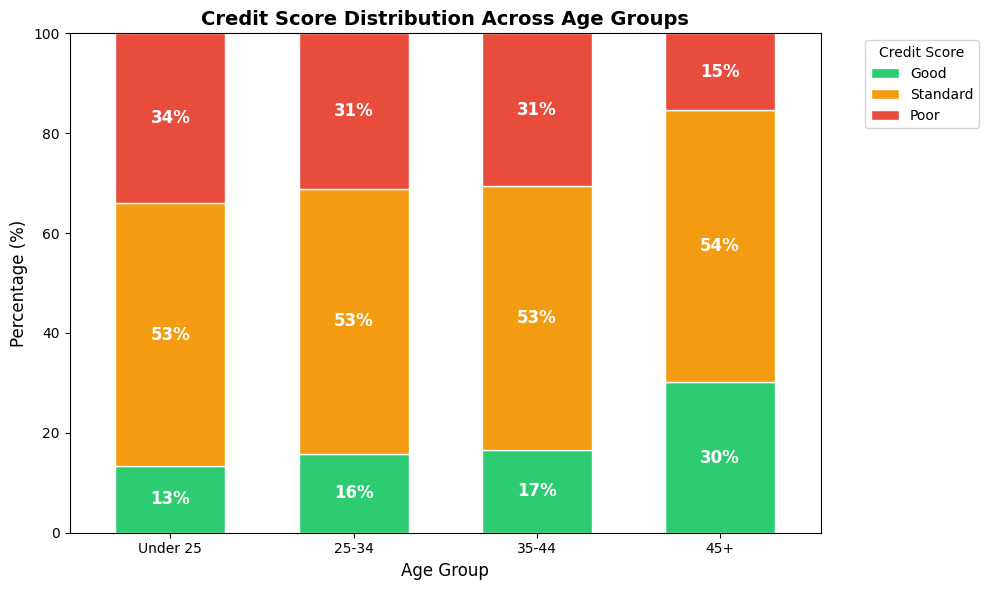

In [30]:
# 1. Prepare data: Group by Age_Group and Credit_Score, then normalize to 100% per age group
age_credit_counts = df.groupby(['Age_Group', 'Credit_Score']).size().unstack(fill_value=0)
age_credit_counts = age_credit_counts.div(age_credit_counts.sum(axis=1), axis=0) * 100

# Order age groups and credit score columns nicely
age_order = ['Under 25', '25-34', '35-44', '45+']
age_credit_counts = age_credit_counts.reindex(age_order)

available_cols = [c for c in ['Good', 'Standard', 'Poor'] if c in age_credit_counts.columns]
age_credit_counts = age_credit_counts[available_cols]

# Consistent color palette for credit scores
colors = {'Good': '#2ecc71', 'Standard': '#f39c12', 'Poor': '#e74c3c'}

# 2. Plotting the Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6), facecolor='white')

age_credit_counts.plot(kind='bar',stacked=True,ax=ax,color=[colors.get(c, '#3498db') for c in age_credit_counts.columns],edgecolor='white', width=0.6)

# 3. Add percentage labels inside each segment
# ax.containers holds one BarContainer per credit score (stack layer)
for container in ax.containers:
    labels = [f'{v:.0f}%' if v > 4 else '' for v in container.datavalues]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=12, fontweight='bold', color='white')

ax.set_title('Credit Score Distribution Across Age Groups', fontsize=14, fontweight='bold')
ax.set_xlabel('Age Group', fontsize=12)
ax.set_ylabel('Percentage (%)', fontsize=12)
ax.set_xticklabels(age_credit_counts.index, rotation=0)
ax.set_ylim(0, 100)
ax.legend(title='Credit Score', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Insight
Customers in the 45+ age group maintain the highest proportion of Good and Standard credit scores and the lowest proportion of Poor credit scores compared to younger cohorts. The 25–44 age brackets exhibit very consistent credit score distributions. Meanwhile, the Under 25 group shows the highest concentration of Poor credit scores and the lowest Good credit scores.
This indicates that older customers generally demonstrate stronger credit discipline and stability over time, whereas younger customers face higher credit risks—likely due to shorter credit histories and developing financial stability.

**Income VS Credit Score**

/tmp/ipykernel_13295/134389018.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Credit_Score',y='Num_of_Loan',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'},ax=axes[0])
/tmp/ipykernel_13295/134389018.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Credit_Score',y='Credit_Utilization_Ratio',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'},ax=axes[1])


Text(0.5, 1.0, 'Credit_Utilization_Ratio VS Credit Score')

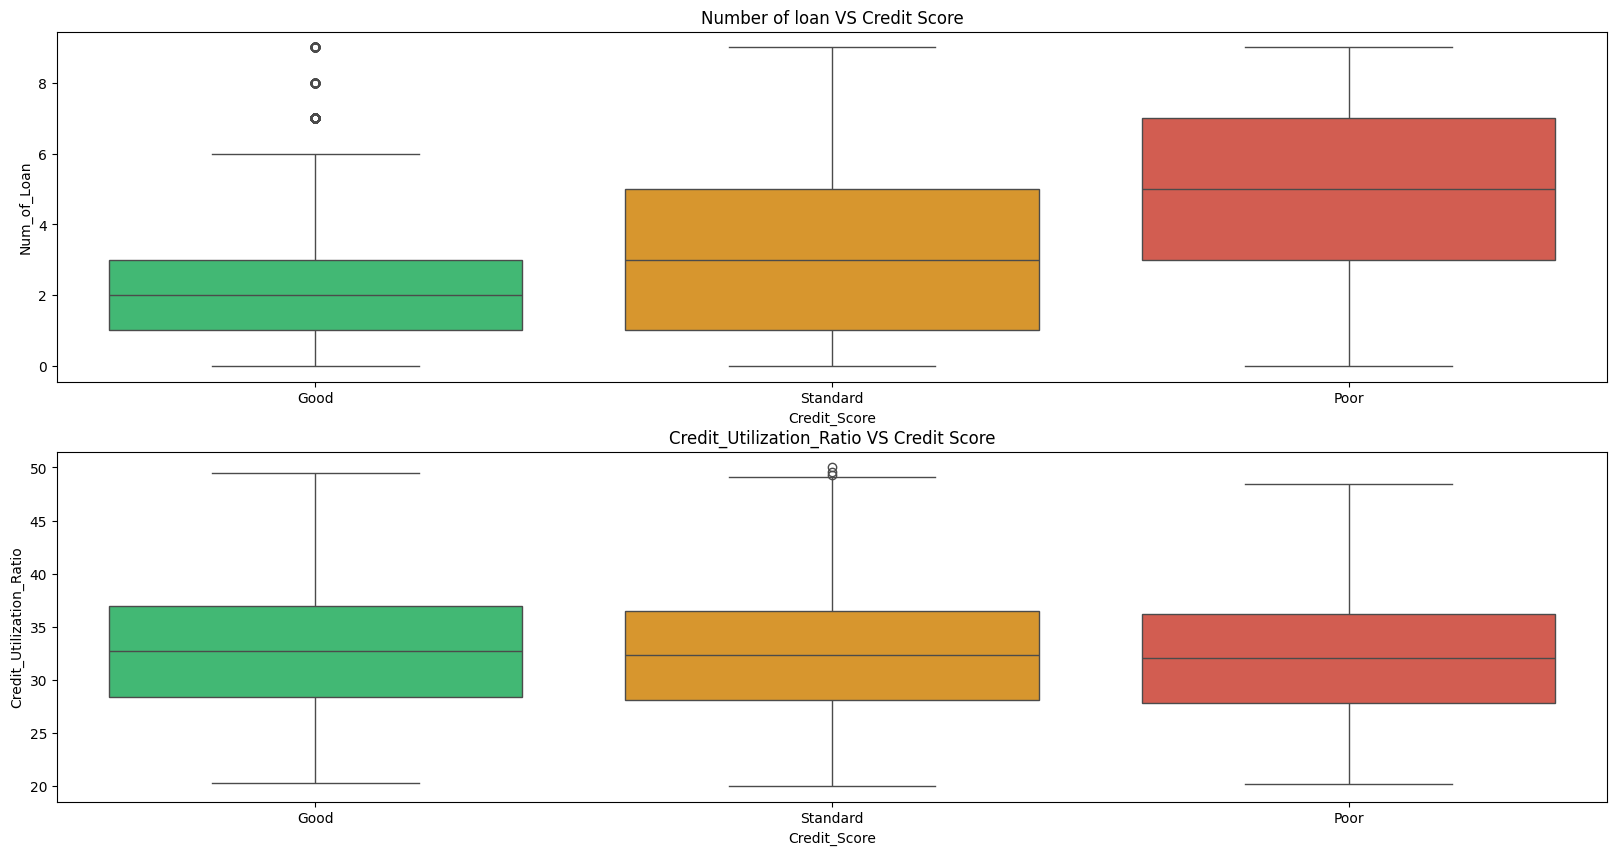

In [31]:
figure,axes=plt.subplots(2,1,figsize=(20,10),facecolor='white')
sns.boxplot(data=df,x='Credit_Score',y='Num_of_Loan',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'},ax=axes[0])
axes[0].set_title("Number of loan VS Credit Score")

sns.boxplot(data=df,x='Credit_Score',y='Credit_Utilization_Ratio',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'},ax=axes[1])
axes[1].set_title("Credit_Utilization_Ratio VS Credit Score")

# Does Credit_utilization_ratio has greater impact on credit_score compared to total number of loans
As per visualisation of "Credit_Utilization_Ratio VS Credit Score":
1. Unexpected Uniformity: Contrary to standard financial expectations where lower credit utilization heavily drives better scores, the box plot shows that the median credit utilization ratio remains nearly identical (around 32% to 33%) across the Good, Standard, and Poor credit score categories.
2. Conclusion: In this specific dataset, the credit utilization ratio does not exhibit a strong visible impact or distinct separation between the credit score tiers, indicating that other features (like loans, payment history, or debt amounts) play a more differentiating role in determining credit health.
But for Number of loan VS Credit Score: Num_of_loan is highly related to credit score showing as number of loan increases credit score decreases (having some outliers as well)

/tmp/ipykernel_13295/2711684146.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Credit_Score',y='Num_Credit_Card',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'})


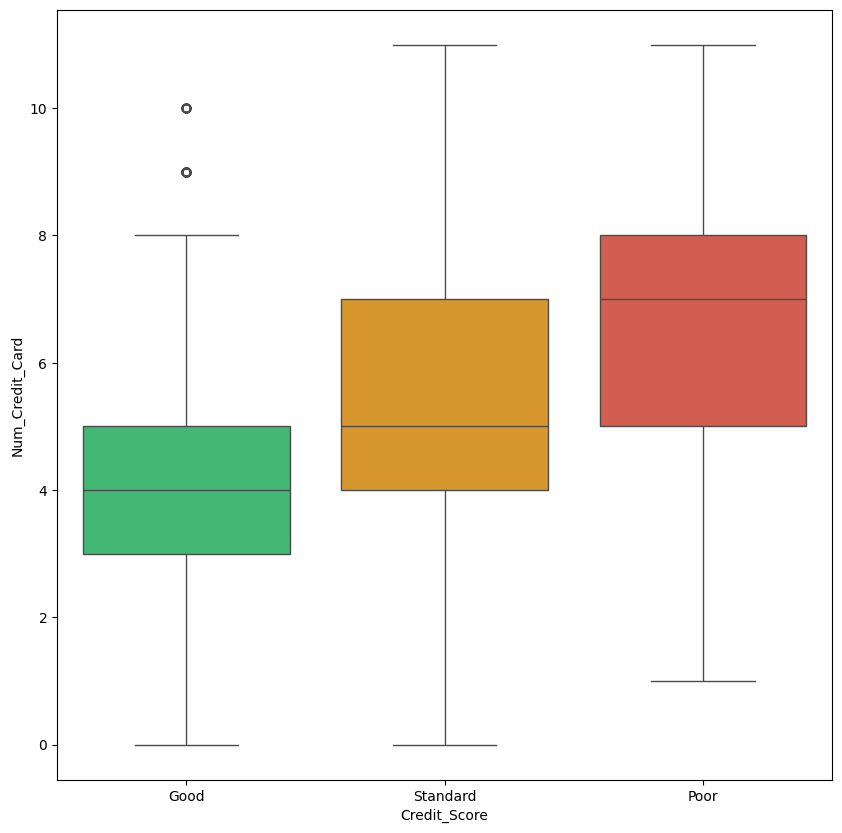

In [32]:
plt.figure(figsize=(10,10),facecolor='white')
sns.boxplot(data=df,x='Credit_Score',y='Num_Credit_Card',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'})
plt.title='Num_Credit_Card VS Credit_Score assuming all records have good Credit_Utilization_Ratio'

# Having high number of credit cards is associated with higher credit score
No,they are inversely proportion i.e having less credit card indicate higher credit score

/tmp/ipykernel_13295/2563112676.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df,x='Credit_Score',y='Num_of_Delayed_Payment',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'})


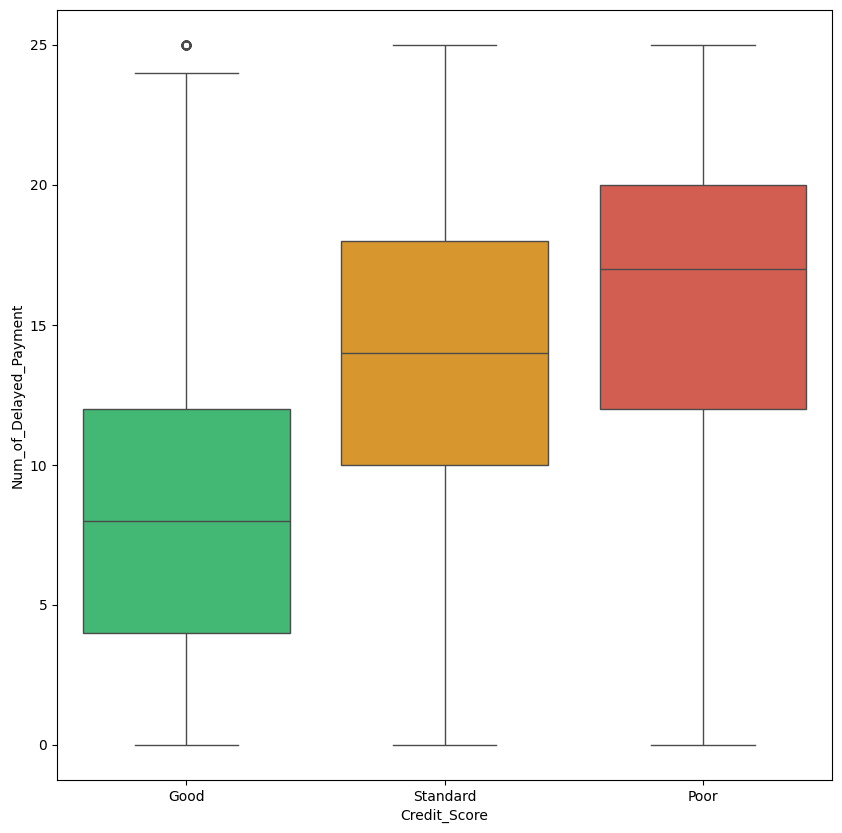

In [33]:
plt.figure(figsize=(10,10),facecolor='white')
sns.boxplot(data=df,x='Credit_Score',y='Num_of_Delayed_Payment',palette={'Good':'#2ecc71','Standard':'#f39c12','Poor':'#e74c3c'})
plt.title='Num_of_Delayed_Payment VS Credit_Score related to correlation'

# Correlation between Num_of_Delayed_Payment and credit score
Correlation is negative

In [34]:
import plotly.express as px


# 1. Select numeric columns (and optionally encode Credit_Score if you want it included)
numeric_df = df.select_dtypes(include=['number'])

# 2. Compute correlation matrix
corr_matrix = numeric_df.corr()

# 3. Creating interactive heatmap using Plotly Express
fig = px.imshow(
    corr_matrix,
    text_auto='.2f',                    # Automatically show correlation values in cells
    color_continuous_scale='RdBu_r',    # Red-Blue diverging color scale (reverse so red is positive, blue is negative)
    zmin=-1, zmax=1,                    # Fix color scale bounds from -1 to 1
    title='Features Correlation Heatmap',
    labels=dict(color="Correlation")
)

fig.update_layout(
    width=1000,
    height=1000,
    title_font_size=20,
    paper_bgcolor='white',
    plot_bgcolor='white'
)

fig.show()

# Final Conclusion
***Factors that matter***


***Income:*** Higher annual in-hand income is linked to better credit scores. Good has the highest median income and Poor the lowest. Many high earners still have Standard or Poor scores, so income helps but does not guarantee a good score.

***Number of loans:*** More loans go with lower credit scores. This is one of the clearest separators between the tiers.

***Delayed payments:*** There is a negative relationship. More delayed payments mean a lower credit score.
Number of credit cards: More cards go with lower scores. Fewer cards indicate a better score.

***Age:*** Customers aged 45+ have the most Good scores and the fewest Poor. The 25-44 groups look similar to each other. Under-25s have the most Poor and the fewest Good, likely because of shorter credit history and less financial stability.


***Factors that do not matter much***


***Credit utilization ratio:*** Median utilization is about 32-33% in all three score groups, so it does not separate them. It is also unrelated to monthly salary. It looks like a weak predictor in this dataset.

***Month:*** The score mix is roughly stable across months, with only minor fluctuations. There is no meaningful seasonal effect.


***Overall***


Credit score in this dataset is driven mainly by borrowing behaviour and repayment discipline (number of loans, number of credit cards, delayed payments), with income and age as secondary factors. Credit utilization and month have little effect.


***Business recommendations***


Prioritise payment history and loan count when assessing risk.

Treat younger customers (under 25) as a higher-risk segment, with closer monitoring or credit-building products.

Do not rely on income alone, since high earners can still have poor scores.

Encourage customers to reduce missed payments and avoid taking on many loans or cards.


***Limitations***


The data appears synthetic or capped (hard limits on salary and utilization), so findings may not match real-world credit behaviour. Real credit scoring usually weights utilization heavily.

Each customer has multiple monthly rows, so counts and percentages are by record, not by unique customer.

Boxplots show association, not causation. Confirming with Spearman correlations or a model would strengthen the conclusions.
